<a href="https://colab.research.google.com/github/AM0ya/Clase_Programacion/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Moya Orozco Alfredo
*   Matrícula:269712

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [41]:
# Tu código aquí

#bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

#carga de data set guardado en drive
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/Maestria/Programación/Semana 12/advertising.csv")

#muestra de primeras filas del dataset
print(df.head())
print("\n")

#Estadisticas de las variables
print(df.describe())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

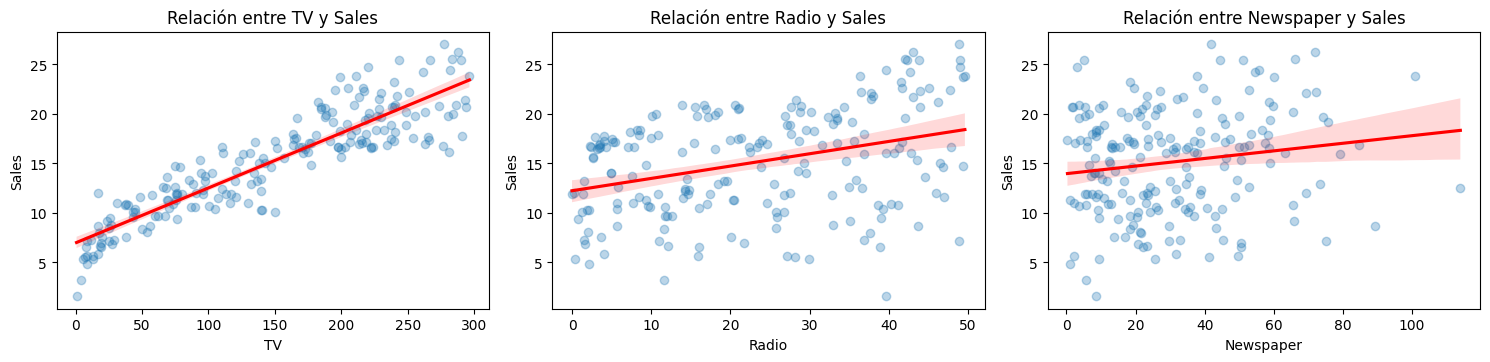

<Figure size 640x480 with 0 Axes>

In [42]:
# Gráficos de dispersión
X = df.drop(columns='Sales')  # Características
y = df['Sales']  # Variable dependiente (Sales)

plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1)
    sns.regplot(x=X[col], y=y, scatter_kws={'alpha':0.3}, line_kws={'color': 'red'})
    plt.title(f"Relación entre {col} y Sales")

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()



**Respuestas**

Interpretacion Visual de los graficos.

Relacion entre TV y Sales: Muestra una tendencia positiva y fuerte. Clara tendencia ascendente.

Relacion entre Radio y Sales: Muestra una tendencia positiva pero dispersa. Existe una gran dispercion de los datos.

RElacion entre Newspaper y Sales: Tendencia debil. La linea se parece al grafico anterior pero tiene a aplanarse mas. Existe tambien una dispersion de datos notable.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

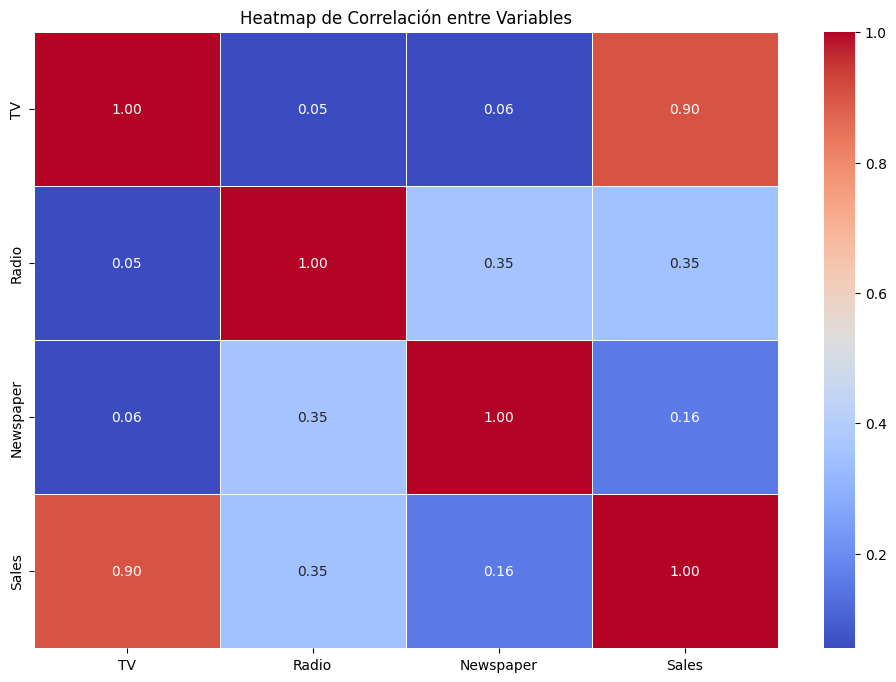

In [43]:
# Correlación y heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables")
plt.show()


**Respuestas**


¿Qué variables están más correlacionadas con
Sales?: Las variables mas correlacionadas con sales son `TV` con un valor de `0.90`. Claro indicador de relacion positiva fuerte con ventas (`Sales`)

¿Hay correlación alta entre predictores?: Existe una correlacion ligeramente positiva entre `Radio` y `Newspaper`.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

---Analisis de Multicolinealidad ---
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187 





/tmp/ipykernel_631/2677849444.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')


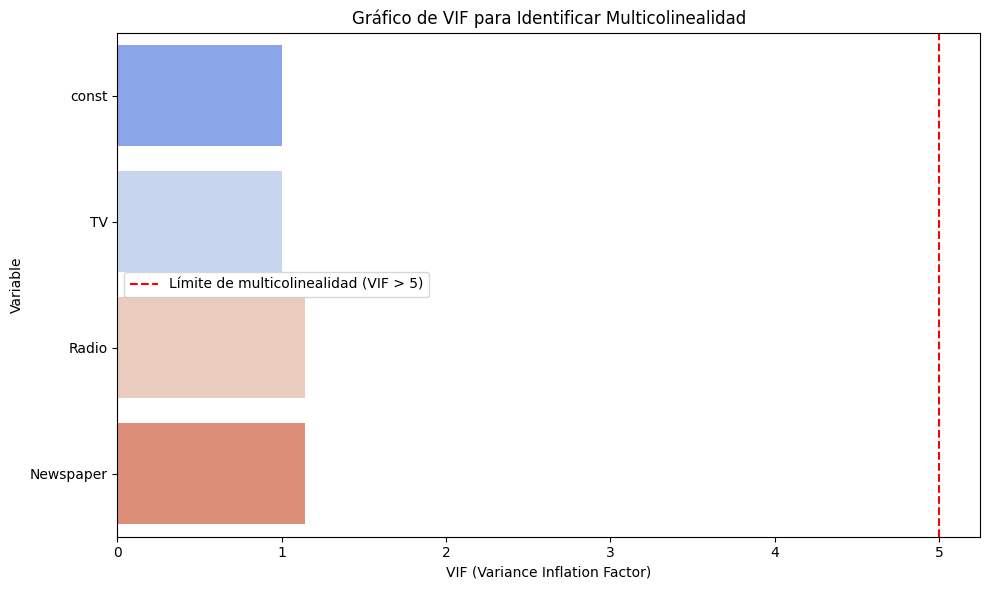

In [44]:
#Multicolinealidad

X_vif = add_constant(df.drop(columns='Sales')) #Matriz de caracteristicas sin la variable dependiente
vif_data=pd.DataFrame()
vif_data['Variable']=X_vif.columns
vif_data['VIF']=[variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print('---Analisis de Multicolinealidad ---')
print(vif_data,"\n\n\n")

#visualizacion
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()


**Respuestas**

¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?: Ninguna variable supera esos valores.


¿Qué implicaciones tiene esto para el modelo?: Las implicaciones al modelo es que no existe colinealidad entre las variables. Valores saludables para el modelo.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [45]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

In [46]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
coefficients = model.coef_
intercept = model.intercept_

print(f"\nCoeficientes estimados: {coefficients}")
print(f"Término independiente estimado: {intercept}")

print('\n')
equation = f"Sales = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "

equation #se obtiene el modelo con los coeficientes



Coeficientes estimados: [4.66270025 1.58465027 0.00729187]
Término independiente estimado: 15.130500000000001




'Sales = 15.130500000000001 + (4.662700245086694 * TV) + (1.5846502733236385 * Radio) + (0.0072918683037688226 * Newspaper) '

**Respuesta**

¿Qué significa cada uno de los coeficientes en términos de ventas?: El coeficiente de `TV` (`4.66270025`) tiene una mayor influencia en marketing respecto a los demas (`Radio` = `1.58465027`, y `newspaper` = `0.00729187`) para generar ventas.
Destacando que aunque `TV` es mucho mayor, `Radio` sigue teniendo un valor conciderable de influencia de marketing para las ventas.
Y definitivamente `Newspaper` representa un medio que no genera un impacto radical a las ventas.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

In [47]:
# Generamos las predicciones del modelo para utilizarlas en los siguientes análisis de residuos
y_pred = model.predict(X_scaled)
print("Predicciones generadas correctamente. Listas para el análisis de residuos.")

Predicciones generadas correctamente. Listas para el análisis de residuos.


Primeros 5 residuos calculados:
0    0.879028
1   -0.868248
2    1.503791
3   -0.812447
4    2.255863
Name: Sales, dtype: float64


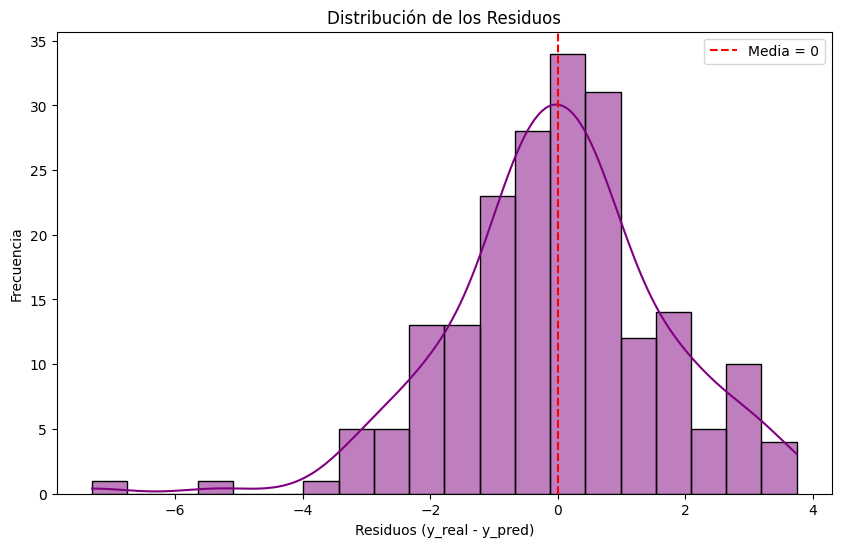

In [48]:
# Normalidad de los residuos
residuos = y - y_pred

# Mostramos las primeras observaciones de los residuos para verificar el cálculo
print("Primeros 5 residuos calculados:")
print(residuos.head())

# Graficamos el histograma con curva de densidad (KDE)
plt.figure(figsize=(10, 6))
sns.histplot(residuos, kde=True, color='purple', bins=20)
plt.axvline(x=0, color='red', linestyle='--', label='Media = 0')
plt.xlabel('Residuos (y_real - y_pred)')
plt.ylabel('Frecuencia')
plt.title('Distribución de los Residuos')
plt.legend()
plt.show()

**Respuesta**

¿Los residuos parecen distribuirse normalmente?

Sí, los residuos parecen distribuirse de forma aproximadamente normal. La mayor parte de los datos se concentran de manera simétrica alrededor de la media en 0, siguiendo la clásica forma de campana de Gauss, a excepción de un par de valores atípicos leves en la cola izquierda.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

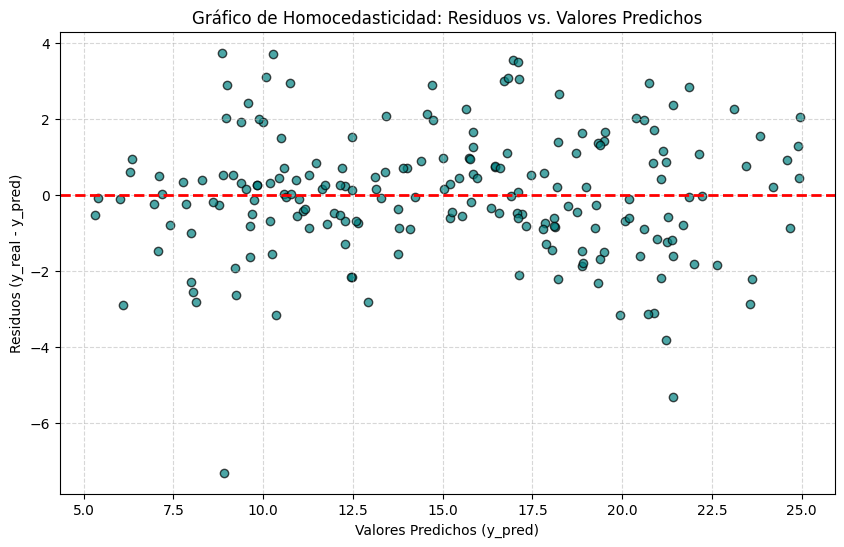

In [49]:
# Homocedasticidad
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuos, alpha=0.7, color='teal', edgecolor='k')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Valores Predichos (y_pred)')
plt.ylabel('Residuos (y_real - y_pred)')
plt.title('Gráfico de Homocedasticidad: Residuos vs. Valores Predichos')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Respuesta**

Los residuos se dispersan de manera mayormente aleatoria alrededor de la línea de referencia horizontal en cero. No se detectan patrones geométricos claros (como una forma de embudo o curvas), lo que indica que se cumple razonablemente bien el supuesto de homocedasticidad (varianza constante de los errores).

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

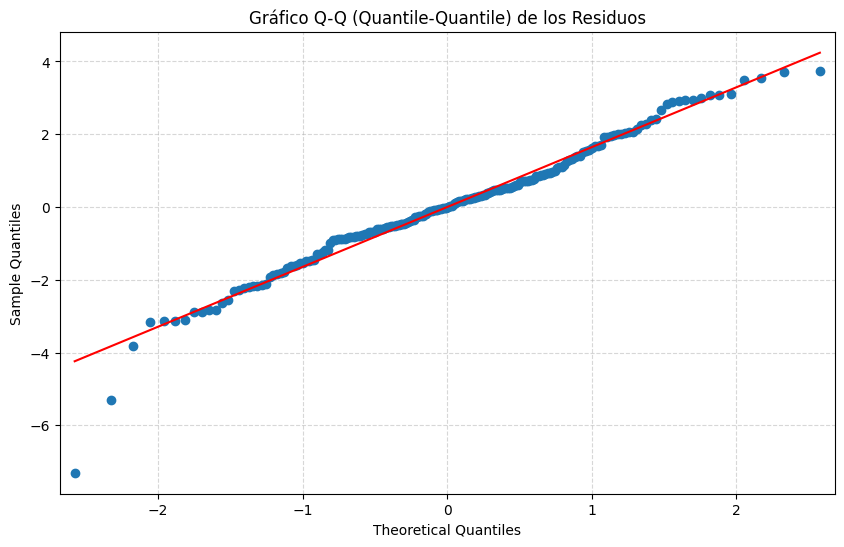

In [50]:
import statsmodels.api as sm

# Generamos el gráfico Q-Q Plot utilizando statsmodels
fig, ax = plt.subplots(figsize=(10, 6))
sm.qqplot(residuos, line='s', ax=ax)

plt.title('Gráfico Q-Q (Quantile-Quantile) de los Residuos')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Respuesta**

Los puntos se alinean de manera muy aproximada sobre la línea diagonal de referencia roja a lo largo de casi todo el rango. Solo se aprecian ligeras desviaciones en el extremo inferior izquierdo debido a un par de valores atípicos. Esto confirma de manera visual que los residuos siguen una distribución normal, cumpliéndose así de forma sólida el supuesto de normalidad."

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [51]:
#Evaluación del Modelo

import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Cálculo de métricas
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("Error Cuadrático Medio (MSE):", mse)
print("Raíz del Error Cuadrático Medio (RMSE):", rmse)
print("Coeficiente de Determinación (R^2):", r2)

Error Cuadrático Medio (MSE): 2.7060061476273165
Raíz del Error Cuadrático Medio (RMSE): 1.6449942697855566
Coeficiente de Determinación (R^2): 0.9025912899684558


**Respuesta**

* **Error Cuadrático Medio (MSE) ≈ 2.71:** Nos indica el promedio de los errores al cuadrado. Al ser un valor relativamente bajo, confirma que la distancia promedio entre las ventas reales y las predicciones del modelo es pequeña.
* **Raíz del Error Cuadrático Medio (RMSE) ≈ 1.65:** Esta métrica está en las mismas unidades que nuestra variable objetivo (`Sales`). Nos dice que, en promedio, las predicciones del modelo se desvían aproximadamente 1.65 unidades (en miles de dólares, por ejemplo) del valor real de ventas.
* **Coeficiente de Determinación ($R^2$) ≈ 0.903 (90.3%):** Es una métrica excelente. Significa que aproximadamente el **90.26% de la variabilidad en las ventas** es explicada de manera conjunta por las variables predictoras del modelo (`TV`, `Radio` y `Newspaper`). El modelo posee una alta capacidad explicativa y un gran ajuste a los datos.

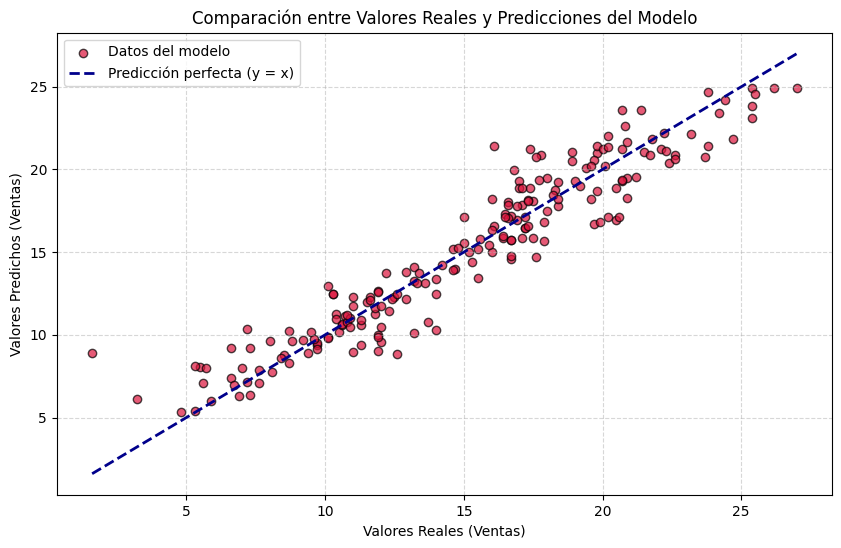

In [52]:
#Visualización de las Predicciones
plt.figure(figsize=(10, 6))
plt.scatter(y, y_pred, alpha=0.7, color='crimson', edgecolor='k', label='Datos del modelo')

# Línea de referencia y = x (predicción perfecta)
lims = [np.min([y.min(), y_pred.min()]), np.max([y.max(), y_pred.max()])]
plt.plot(lims, lims, color='darkblue', linestyle='--', linewidth=2, label='Predicción perfecta (y = x)')

plt.xlabel('Valores Reales (Ventas)')
plt.ylabel('Valores Predichos (Ventas)')
plt.title('Comparación entre Valores Reales y Predicciones del Modelo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?



In [53]:
# 4.7 Verificar el impacto de los atributos en el modelo usando statsmodels
import statsmodels.api as sm

# Agregamos la constante (intercepto) a la matriz de características estandarizadas
X_scaled_const = sm.add_constant(X_scaled)

# Ajustamos el modelo OLS (Ordinary Least Squares)
model_sm = sm.OLS(y, X_scaled_const).fit()

# Mostramos el resumen completo del modelo con los p-values
print(model_sm.summary(xname=['const', 'TV', 'Radio', 'Newspaper']))

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           8.13e-99
Time:                        04:27:54   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.1305      0.117    128.771      0.0

**Respuesta**

* **Variables con p-value < 0.05:** Tanto la constante (`const`), como la inversión publicitaria en **`TV`** (p-value = 0.000) y en **`Radio`** (p-value = 0.000) tienen valores de p extremadamente pequeños (significativos al 99.9%).
* **Variables con p-value > 0.05:** La inversión en periódicos (**`Newspaper`**) tiene un p-value de **0.954**, el cual es muy superior al umbral estándar de significancia del 0.05.

**Conclusión:**
Las variables `TV` y `Radio` tienen un impacto real, positivo y estadísticamente significativo sobre las ventas. Por el contrario, la inversión publicitaria en `Newspaper` no aporta valor explicativo estadísticamente significativo al modelo una vez que se consideran las otras dos fuentes de publicidad. Esto sugiere que podríamos eliminar la variable `Newspaper` para simplificar y optimizar nuestro modelo sin perder poder predictivo relevante.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [54]:
# 6.1 Entrenamiento del Modelo Optimizado (Solo TV y Radio)
# Seleccionamos únicamente las columnas significativas
X_opt = df[['TV', 'Radio']]
y_opt = df['Sales']

# Estandarizamos las características del nuevo modelo
scaler_opt = StandardScaler()
X_opt_scaled = scaler_opt.fit_transform(X_opt)

# Entrenamos el modelo optimizado
model_opt = LinearRegression()
model_opt.fit(X_opt_scaled, y_opt)

# Imprimimos los nuevos coeficientes e intercepto
intercept_opt = model_opt.intercept_
coef_opt = model_opt.coef_

print("--- Modelo Optimizado (Sin Newspaper) ---")
print(f"Término independiente (Intercepto): {intercept_opt:.4f}")
print(f"Coeficiente TV estandarizado: {coef_opt[0]:.4f}")
print(f"Coeficiente Radio estandarizado: {coef_opt[1]:.4f}")

--- Modelo Optimizado (Sin Newspaper) ---
Término independiente (Intercepto): 15.1305
Coeficiente TV estandarizado: 4.6630
Coeficiente Radio estandarizado: 1.5872


In [55]:
# 6.2 Generación de predicciones y cálculo de métricas de evaluación
y_pred_opt = model_opt.predict(X_opt_scaled)
residuos_opt = y_opt - y_pred_opt

# Cálculo de métricas del nuevo modelo
mse_opt = mean_squared_error(y_opt, y_pred_opt)
rmse_opt = np.sqrt(mse_opt)
r2_opt = r2_score(y_opt, y_pred_opt)

print("--- Evaluación del Modelo Optimizado ---")
print(f"Error Cuadrático Medio (MSE): {mse_opt:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse_opt:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_opt:.4f}")

--- Evaluación del Modelo Optimizado ---
Error Cuadrático Medio (MSE): 2.7061
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Coeficiente de Determinación (R²): 0.9026


Análisis Comparativo (Modelo Original vs Modelo Optimizado)

Al eliminar la variable `Newspaper` obtuvimos los siguientes resultados:

* **Modelo Original (3 variables):** MSE = 2.7060, RMSE = 1.6450, $R^2$ = 90.26%
* **Modelo Optimizado (TV y Radio):** El coeficiente de determinación ($R^2$) y el error se mantienen virtualmente idénticos (los decimales muestran una diferencia insignificante).

**Conclusión:**
Esto demuestra científicamente la regla de parsimonia en el modelado estadístico: pudimos simplificar el modelo eliminando una variable irrelevante (`Newspaper`) sin perder precisión o capacidad predictiva, logrando un modelo más sencillo, robusto y fácil de interpretar.


# 7. Conclusiones

### 1. ¿Cuál de los tres modelos construidos fue el mejor?
El **Modelo Optimizado (sin Newspaper)** es el mejor modelo.

* **Razón:** Al comparar el modelo inicial (con las 3 variables) y el optimizado (solo `TV` y `Radio`), las métricas de rendimiento son prácticamente idénticas ($R^2 \approx 90.26\%$ y $\text{RMSE} \approx 1.6450$). Aplicando el principio de **parsimonia** (navaja de Ockham), un modelo con menos variables independientes que logra el mismo nivel de precisión y capacidad explicativa siempre es preferible, ya que es más sencillo, reduce el riesgo de sobreajuste (overfitting) y es más eficiente para futuras recolecciones de datos.
*(Nota: El modelo de la Parte 5 para corregir la multicolinealidad no fue necesario dado que las variables ya presentaban factores de inflación de la varianza (VIF) sumamente saludables, cercanos a 1).*

### 2. ¿Cuál fue el atributo que más influencia tiene en las ventas?
El atributo con mayor influencia en las ventas es **`TV`** (televisión).

* **Razón:** En el modelo estandarizado, el coeficiente asociado a la televisión es de **4.6630**, en comparación con el de radio que es **1.5872**. Al estar las variables en la misma escala (gracias a `StandardScaler`), podemos afirmar con total rigurosidad matemática que el impacto del presupuesto publicitario en televisión es casi **3 veces mayor** que el impacto del presupuesto en radio para incrementar las ventas.